# EMQA_L1_bg_battery

**Case study: Romania-Bulgaria evening price gap and Bulgarian batteries**

Energy Markets Quantitative Analysis (EMQA), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L1/EMQA_L1_bg_battery/EMQA_L1_bg_battery.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Monthly Romania minus Bulgaria day-ahead price spread in the evening hours 19:00-22:00 local time (EET) since 2023, and the monthly mean Bulgarian battery discharge and charging (MW) since the battery series starts; an association, not proof.

**Data:** 2023-01 to 2026-10, local time; BG battery series reported from 2026-09-10. **Source:** energy-charts.info (Fraunhofer ISE); ENTSO-E (Transelectrica data for Romania).

The numbers printed below are those on the slide; the tag `[key]` is their name in `lectures/L1/L1_numbers.json`.

In [2]:
import json
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per bidding zone
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZONES = ['RO', 'BG', 'HU', 'DE_LU']
ZONE_NAME = {'RO': 'Romania (OPCOM PZU)', 'BG': 'Bulgaria (IBEX)', 'HU': 'Hungary (HUPX)', 'DE_LU': 'Germany-Luxembourg'}
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
ZONE_SHORT = {'RO': 'RO (OPCOM PZU)', 'BG': 'BG (IBEX)', 'HU': 'HU (HUPX)', 'DE_LU': 'DE-LU (EPEX SPOT)'}


def month_ticks(ax, step=1):
    """Month axis 1..12: every month named, written vertically so it fits."""
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels([MON_EN[m - 1] if (m - 1) % step == 0 else '' for m in range(1, 13)], fontsize=9, rotation=90)


def legend_bottom(fig, ncol=4, y=0.0):
    """One legend centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l_ in zip(*ax.get_legend_handles_labels()):
            if l_ not in labels:
                handles.append(h)
                labels.append(l_)
    if handles:
        fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
                   handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Round as on the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')


def show(key, label, value):
    """Print a number of the slide; [key] = its name in lectures/L1/L1_numbers.json."""
    print(f'{label} = {value}   [{key}]')

## Data
Real series from the course repository (see `data/SOURCES.md`), cut at the last complete month; missing values stay missing.

In [3]:
# data cut-off: last complete calendar month common to the Romanian prices and the generation data
_p = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')['RO']
_g = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', usecols=['date_cet', 'hydro_run_of_river'],
                 parse_dates=['date_cet']).set_index('date_cet')['hydro_run_of_river']
_last = min(_p.dropna().index.max(), _g.dropna().index.max())
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
END_UTC = (END + pd.Timedelta(days=1)).tz_localize('Europe/Brussels').tz_convert('UTC')   # end of the CET day, in UTC
Y = END.year
print('data cut-off:', END.date())

# native-resolution day-ahead prices (60-min until Sep 2025, 15-min from 1 Oct 2025), CET/CEST clock
X = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
X.index = X.index.tz_convert('Europe/Brussels')
X = X.loc[:str(END.date())]
# Bulgarian generation (incl. battery discharge and charging), hourly mean MW (UTC)
BGH = pd.read_csv(DATA + 'generation_bg_mw_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
BGH = BGH.loc[BGH.index < END_UTC]

data cut-off: 2026-10-31


## Computation

In [4]:
XL = X.copy()
XL.index = XL.index.tz_convert('Europe/Bucharest')              # local time, same in Romania and Bulgaria
wloc = XL['mtu_minutes'] / 60                                   # duration weights (60- and 15-min MTUs)


def wmean(z, mask):
    v, ww = XL.loc[mask, z], wloc[mask]
    ok = v.notna()
    return float((v[ok] * ww[ok]).sum() / ww[ok].sum())


ev, mid = {}, {}
for y in [2023, 2024, 2025, Y]:
    base = (XL.index.year == y) & (XL.index.month >= 4) & (XL.index.month <= 9)  # April-September
    ev[y] = {z: fl(wmean(z, base & (XL.index.hour >= 19) & (XL.index.hour <= 21)), 1) for z in ['RO', 'BG']}
    mid[y] = {z: fl(wmean(z, base & (XL.index.hour >= 11) & (XL.index.hour <= 14)), 1) for z in ['RO', 'BG']}
evm = XL[(XL.index.hour >= 19) & (XL.index.hour <= 21)].loc['2023-01-01':]
evw = evm['mtu_minutes'] / 60
mk = evm.index.tz_localize(None).to_period('M')
ev_sp = ((evm['RO'] - evm['BG']) * evw).groupby(mk).sum() / evw.groupby(mk).sum()   # monthly RO - BG evening spread
bat = BGH[['battery', 'battery_consumption']].copy()
bat.index = bat.index.tz_convert('Europe/Bucharest')
bat_first = bat.dropna(how='all').index.min()
bb = bat.loc[bat_first:]
batm = bb.groupby(bb.index.tz_localize(None).to_period('M')).mean()
for y in [2025, Y]:
    for z in ['RO', 'BG']:
        show(f'bat.evening.{y}.{z}', f'{z}, Apr-Sep {y}, 19:00-22:00 EET, EUR/MWh', ev[y][z])
for z in ['RO', 'BG']:
    show(f'bat.midday.{Y}.{z}', f'{z}, Apr-Sep {Y}, 11:00-15:00 EET, EUR/MWh', mid[Y][z])
show('bat.bg_first', 'first reported BG battery hour', bat_first.strftime('%Y-%m-%d'))
show('bat.gap_open', f'first month of {Y} with an evening spread > 15 EUR/MWh',
     next((k.strftime('%Y-%m') for k, v in ev_sp.items() if k.year == Y and v > 15), 'none'))

RO, Apr-Sep 2025, 19:00-22:00 EET, EUR/MWh = 171.1   [bat.evening.2025.RO]
BG, Apr-Sep 2025, 19:00-22:00 EET, EUR/MWh = 169.7   [bat.evening.2025.BG]
RO, Apr-Sep 2026, 19:00-22:00 EET, EUR/MWh = 215.5   [bat.evening.2026.RO]
BG, Apr-Sep 2026, 19:00-22:00 EET, EUR/MWh = 178.0   [bat.evening.2026.BG]
RO, Apr-Sep 2026, 11:00-15:00 EET, EUR/MWh = 48.1   [bat.midday.2026.RO]
BG, Apr-Sep 2026, 11:00-15:00 EET, EUR/MWh = 46.0   [bat.midday.2026.BG]
first reported BG battery hour = 2026-09-10   [bat.bg_first]
first month of 2026 with an evening spread > 15 EUR/MWh = 2026-05   [bat.gap_open]


## Chart

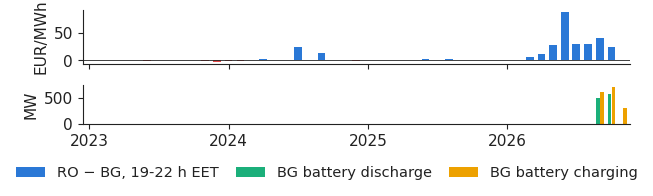

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(6.4, 2.0), sharex=True, gridspec_kw={'height_ratios': [1.4, 1]})
xi = ev_sp.index.to_timestamp()
axs[0].bar(xi, ev_sp.values, width=20, color=[PAL['RO'] if v >= 0 else PAL['c8'] for v in ev_sp.values],
           label='RO − BG, 19-22 h EET')
axs[0].axhline(0, color='#222222', lw=0.6)
axs[0].set_ylabel('EUR/MWh')
bi = batm.index.to_timestamp()
axs[1].bar(bi - pd.Timedelta(days=5), batm['battery'].values, width=9, color=PAL['HU'], label='BG battery discharge')
axs[1].bar(bi + pd.Timedelta(days=5), -batm['battery_consumption'].values, width=9, color=PAL['BG'], label='BG battery charging')
axs[1].set_ylabel('MW')
axs[1].set_xlim(pd.Timestamp('2022-12-15'), END + pd.Timedelta(days=20))
axs[1].xaxis.set_major_locator(mdates.YearLocator())
axs[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.14, 1, 1))
plt.savefig('bg_battery.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()